In [1]:
import pandas as pd
import numpy as np
# load data
data=pd.read_csv('btc_final.csv')
# adjust date and sort it chronologically 
data['date']=pd.to_datetime(data['date'], dayfirst=True)
data=data.sort_values('date').reset_index(drop=True)
# calculate simple daily returns
data['btc_returns']=data['bt_close'].pct_change()
data['sp_returns']=data['sp_close'].pct_change()
#returns dataset
returns=data[['btc_returns','sp_returns']].dropna()
print('Dataset shape: ',returns.shape)
print('\nReturns')
print(returns.head())
print('\nSummary Stats')
print(returns.describe)

Dataset shape:  (1972, 2)

Returns
   btc_returns  sp_returns
1     0.151515   -0.965261
2    -0.065789    0.192980
3    -0.323944   -0.607435
4    -0.229167    1.549432
5    -0.216216    0.686942

Summary Stats
<bound method NDFrame.describe of       btc_returns  sp_returns
1        0.151515   -0.965261
2       -0.065789    0.192980
3       -0.323944   -0.607435
4       -0.229167    1.549432
5       -0.216216    0.686942
...           ...         ...
1968    -0.036595   -0.012148
1969     0.014486    0.011788
1970     0.004284    0.002734
1971     0.019115    0.017080
1972     0.033328   -0.000796

[1972 rows x 2 columns]>


In [2]:
# Check for infinite values
print("Infinite values:")
print(np.isinf(returns).sum())

# Check for NaN values
print("\nNaN values:")
print(returns.isna().sum())

# Show the rows where BTC or S&P returns are infinite
print("\nRows containing infinity:")
print(
    data.loc[
        np.isinf(data["btc_returns"]) | np.isinf(data["sp_returns"]),
        ["date", "bt_close", "sp_close", "btc_returns", "sp_returns"]
    ]
)

Infinite values:
btc_returns    1
sp_returns     1
dtype: int64

NaN values:
btc_returns    0
sp_returns     0
dtype: int64

Rows containing infinity:
         date  bt_close  sp_close  btc_returns  sp_returns
58 2013-06-25  0.001801  0.011004     0.029412         inf
69 2013-07-06  0.000103  0.043310          inf         0.0


In [3]:
returns=returns.replace([np.inf,-np.inf],np.nan)
returns=returns.dropna()

In [4]:
# expected returns
mu=returns.mean()
# covariance matrix
sigma=returns.cov()
#correlation matrix
corr=returns.corr()

print('Expected Returns')
print(mu)
print('\nCovariance Matrix')
print(sigma)
print('\nCorrelation Matrix')
print(corr)


Expected Returns
btc_returns    0.005222
sp_returns     0.003421
dtype: float64

Covariance Matrix
             btc_returns  sp_returns
btc_returns     0.006847   -0.000501
sp_returns     -0.000501    0.005799

Correlation Matrix
             btc_returns  sp_returns
btc_returns     1.000000   -0.079562
sp_returns     -0.079562    1.000000


In [5]:
result=[]
for btc_w in np.linspace(1,0,101):
    sp_w=1-btc_w
    w=np.array([btc_w,sp_w])
    # expected daily return
    day_ret=w@mu
    # daily variance
    day_var=w@sigma@w
    # daily volatility
    day_vola=np.sqrt(day_var)
    # annually
    ann_ret=day_ret*252
    ann_vola=day_vola*np.sqrt(252)
    # sharpe
    sharpe=(ann_ret-0.04)/ann_vola
    result.append([btc_w,sp_w,ann_ret,ann_vola,sharpe])
result=pd.DataFrame(result, columns=["BTC_w","SP_w","Ann_ret","Ann_vola","sharpe"])
best=result.loc[result['sharpe'].idxmax()]
result
                    


    

,BTC_w,SP_w,Ann_ret,Ann_vola,sharpe
0,1.00,0.00,1.315874,1.313589,0.971289
1,0.99,0.01,1.311336,1.299547,0.978291
2,0.98,0.02,1.306797,1.285619,0.985359
3,0.97,0.03,1.302258,1.271810,0.992490
4,0.96,0.04,1.297720,1.258122,0.999681
...,...,...,...,...,...
96,0.04,0.96,0.880176,1.157498,0.725855
97,0.03,0.97,0.875638,1.170106,0.714156
98,0.02,0.98,0.871099,1.182870,0.702613
99,0.01,0.99,0.866561,1.195785,0.691228


In [6]:
best

BTC_w       0.550000
SP_w        0.450000
Ann_ret     1.111641
Ann_vola    0.869107
sharpe      1.233037
Name: 45, dtype: float64

Text(0, 0.5, 'Sharpes ratio')

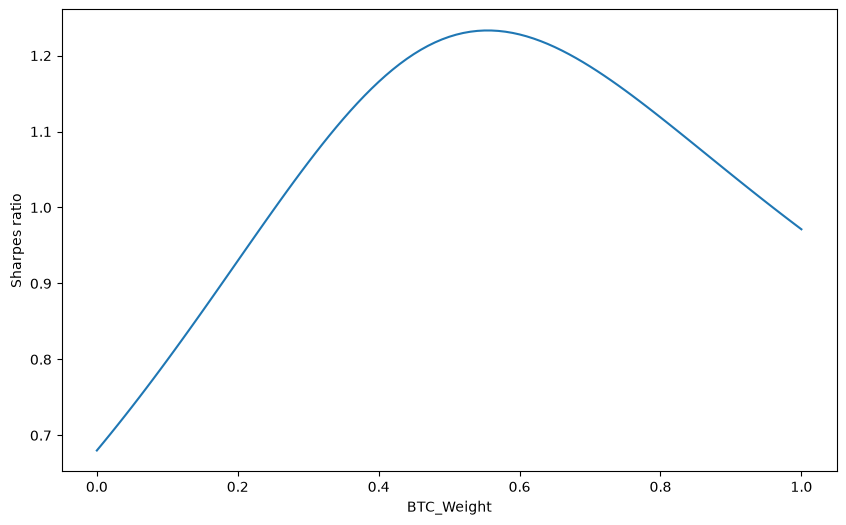

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.plot(result['BTC_w'],result['sharpe'])
plt.xlabel('BTC_Weight')
plt.ylabel('Sharpes ratio')

    

In [8]:
from scipy.optimize import minimize
def negative_sharpe(weights):
    port_ret= weights@mu
    port_var=weights@sigma@weights
    port_vola=np.sqrt(port_var)
    annual_ret= port_ret*252
    annual_vola=port_vola*np.sqrt(252)
    sharpe=(annual_ret-0.04)/annual_vola
    return -sharpe
    

In [9]:
constraints={
    "type" : "eq",
    "fun" : lambda weights:np.sum(weights)-1
}

In [10]:
bounds=(
    (0,1),
    (0,1)
)
initial_weights=np.array([0.5,0.5])

In [11]:
optimization=minimize(
    negative_sharpe,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)
optimization

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -1.2330985764362197
           x: [ 5.550e-01  4.450e-01]
         nit: 3
         jac: [-4.551e-02 -4.646e-02]
        nfev: 10
        njev: 3
 multipliers: [-4.593e-02]

In [12]:
optim_W=optimization.x

In [13]:
portfolio_return= optim_W@mu.values
portfolio_variance= optim_W@sigma.values@optim_W
portfolio_volatility= np.sqrt(portfolio_variance)
annual_returns=portfolio_return*252
annual_volatility=portfolio_volatility*np.sqrt(252)
sharpes_ratio=(annual_returns-0.04)/annual_volatility
print('Daily Portfolio Return:',portfolio_return)
print('\nDaily Portfolio Variance:',portfolio_variance)
print('\nDaily Portfolio Volatility:',portfolio_volatility)
print('\nAnnual Return:',annual_returns)
print('\nAnnual Volatility:',annual_volatility)
print('\nSharpes Ratio:',sharpes_ratio)

Daily Portfolio Return: 0.0044201972711259115

Daily Portfolio Variance: 0.0030097001528532593

Daily Portfolio Volatility: 0.054860734162543424

Annual Return: 1.1138897123237297

Annual Volatility: 0.8708871560190915

Sharpes Ratio: 1.2330985764362197


In [14]:
print("SciPy Sharpe:", -optimization.fun)
print("Manual Sharpe:", sharpes_ratio)
print("Difference:", abs((-optimization.fun) - sharpes_ratio))

SciPy Sharpe: 1.2330985764362197
Manual Sharpe: 1.2330985764362197
Difference: 0.0


In [15]:
print(data.shape)
print(data.columns.tolist())
#print(data[['date','bt_close','btc_returns','sp_close','sp_returns','target']].head(10))
data['target']=data['btc_returns'].shift(-1)
print(data[['date','bt_close','btc_returns','sp_close','sp_returns','target']].head(10))

(1973, 27)
['Unnamed: 0', 'bt_close', 'bt_volume', 'bt_day_diff', 'bt_close_off_high', 'bt_volatility', 'eur_exch_rate', 'jpy_exch_rate', 'cny_exch_rate', 'google_trends_bitcoin', 'avg_block_size', 'transactions', 'difficulty', 'bchain_size', 'mining_revenue', 'hash_rate', 'cost_per_transaction', 'sp_close', 'dj_close', 'nasdaq_close', 'vix_close', 'gold_am', 'silver', 'oil_price', 'date', 'btc_returns', 'sp_returns']
        date  bt_close  btc_returns  sp_close  sp_returns    target
0 2013-04-28  0.003397          NaN  0.435075         NaN  0.151515
1 2013-04-29  0.003912     0.151515  0.015114   -0.965261 -0.065789
2 2013-04-30  0.003654    -0.065789  0.018031    0.192980 -0.323944
3 2013-05-01  0.002471    -0.323944  0.007078   -0.607435 -0.229167
4 2013-05-02  0.001904    -0.229167  0.018046    1.549432 -0.216216
5 2013-05-03  0.001493    -0.216216  0.030442    0.686942  0.517242
6 2013-05-04  0.002265     0.517242  0.030442    0.000000  0.068182
7 2013-05-05  0.002419     0.06818

In [16]:
x=data.drop('target',axis=1)
features=['bt_close', 'bt_volume', 'bt_day_diff', 'bt_close_off_high', 'bt_volatility', 'eur_exch_rate',
          'jpy_exch_rate', 'cny_exch_rate', 'google_trends_bitcoin', 'avg_block_size', 'transactions', 
          'difficulty', 'bchain_size', 'mining_revenue', 'hash_rate', 'cost_per_transaction', 'sp_close',
          'dj_close', 'nasdaq_close', 'vix_close', 'gold_am', 
          'silver', 'oil_price', 'btc_returns', 'sp_returns']
print(len(features))
x2=data[features]
y=data['target']

25


In [17]:
model_data=pd.concat([x2,y],axis=1)
model_data=model_data.replace([np.inf,-np.inf],np.nan)
model_data=model_data.dropna()
X=model_data[features]
Y=model_data['target']
print("X shape:", X.shape)
print("y shape:", Y.shape)

print("\nInfinite values in X:", np.isinf(X).sum().sum())
print("Infinite values in y:", np.isinf(Y).sum())


X shape: (1968, 25)
y shape: (1968,)

Infinite values in X: 0
Infinite values in y: 0


In [18]:
print('First Date:',data.loc[model_data.index[0],'date'])
print('\nLast Date:',data.loc[model_data.index[-1],'date'])
print('\nNo. of Observations:', len(X))

First Date: 2013-04-29 00:00:00

Last Date: 2018-09-20 00:00:00

No. of Observations: 1968


In [19]:
split_index=int(len(X)*0.8)
x_train=X.iloc[:split_index]
x_test=X.iloc[split_index:]
y_train=Y.iloc[:split_index]
y_test=Y.iloc[split_index:]
print('x_train shape:', x_train.shape)
print('x_test shape:', x_test.shape)
print('y_train shape:',y_train.shape)
print('y_test shape:', y_test.shape)

x_train shape: (1574, 25)
x_test shape: (394, 25)
y_train shape: (1574,)
y_test shape: (394,)


In [20]:
print('Training Period')
print(data.loc[x_train.index[0],'date'])
print('to')
print(data.loc[x_train.index[-1],'date'])

print('Testing Period')
print(data.loc[x_test.index[0],'date'])
print('to')
print(data.loc[x_test.index[-1],'date'])

Training Period
2013-04-29 00:00:00
to
2017-08-22 00:00:00
Testing Period
2017-08-23 00:00:00
to
2018-09-20 00:00:00


In [21]:
print('Infinite values in x_train')
print(np.isinf(x_train).sum().sort_values(ascending=False))
print('\nInfinite values in x_test')
print(np.isinf(x_test).sum().sort_values(ascending=False))

Infinite values in x_train
bt_close                 0
bt_volume                0
bt_day_diff              0
bt_close_off_high        0
bt_volatility            0
eur_exch_rate            0
jpy_exch_rate            0
cny_exch_rate            0
google_trends_bitcoin    0
avg_block_size           0
transactions             0
difficulty               0
bchain_size              0
mining_revenue           0
hash_rate                0
cost_per_transaction     0
sp_close                 0
dj_close                 0
nasdaq_close             0
vix_close                0
gold_am                  0
silver                   0
oil_price                0
btc_returns              0
sp_returns               0
dtype: int64

Infinite values in x_test
bt_close                 0
bt_volume                0
bt_day_diff              0
bt_close_off_high        0
bt_volatility            0
eur_exch_rate            0
jpy_exch_rate            0
cny_exch_rate            0
google_trends_bitcoin    0
avg_block_size 

In [22]:
print("Current X:")
print(np.isinf(X).sum().sort_values(ascending=False))

print("\nCurrent y:")
print(np.isinf(Y).sum())

Current X:
bt_close                 0
bt_volume                0
bt_day_diff              0
bt_close_off_high        0
bt_volatility            0
eur_exch_rate            0
jpy_exch_rate            0
cny_exch_rate            0
google_trends_bitcoin    0
avg_block_size           0
transactions             0
difficulty               0
bchain_size              0
mining_revenue           0
hash_rate                0
cost_per_transaction     0
sp_close                 0
dj_close                 0
nasdaq_close             0
vix_close                0
gold_am                  0
silver                   0
oil_price                0
btc_returns              0
sp_returns               0
dtype: int64

Current y:
0


In [23]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

print('Xtr_scaled:', x_train.shape)
print('Xte_scaled:', x_test.shape)

Xtr_scaled: (1574, 25)
Xte_scaled: (394, 25)


In [24]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](25,)","[-0.03, 0.01,-0.01,..., 0. , 0. , 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.004539
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(25)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](25,)","[128.48, 84.38, 58.7 ,..., 3.89, 1.94, 1.67]"


In [25]:
coefficients=pd.DataFrame({
    "Features":features,
    "Coefficients":model.coef_
})
coefficients['Absolute Coefficient']=coefficients['Coefficients'].abs()
coefficients=coefficients.sort_values('Absolute Coefficient',ascending=False)
print(coefficients)

                 Features  Coefficients  Absolute Coefficient
11             difficulty      0.037420              0.037420
0                bt_close     -0.033222              0.033222
12            bchain_size      0.027403              0.027403
16               sp_close      0.024513              0.024513
17               dj_close     -0.023962              0.023962
7           cny_exch_rate      0.022615              0.022615
18           nasdaq_close     -0.014093              0.014093
20                gold_am     -0.013169              0.013169
9          avg_block_size     -0.011605              0.011605
15   cost_per_transaction      0.010186              0.010186
13         mining_revenue     -0.009336              0.009336
1               bt_volume      0.008342              0.008342
6           jpy_exch_rate      0.007568              0.007568
2             bt_day_diff     -0.006629              0.006629
3       bt_close_off_high     -0.006297              0.006297
8   goog

In [26]:
y_pred=model.predict(x_test)
print("First 10 tested prediction")
print("Predicted Values:",y_pred[:10])
print("First 10 real values")
print("Real Values:", y_test.head(10))

First 10 tested prediction
Predicted Values: [-0.08341949 -0.0677839  -0.08195055 -0.07253777 -0.08101826 -0.06568791
 -0.06827238 -0.06641328 -0.06933272 -0.0618595 ]
First 10 real values
Real Values: 1578    0.044820
1579    0.008673
1580   -0.004416
1581    0.007003
1582    0.000000
1583    0.045665
1584   -0.003104
1585    0.030687
1586    0.040777
1587   -0.065091
Name: target, dtype: float64


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:",rmse)
print('R2:',r2)

MAE: 0.08707531166644643
MSE: 0.01054891704699481
RMSE: 0.10270792105283219
R2: -3.1188153617228114


In [28]:
baseline_prediction=y_train.mean()
baseline_mae=mean_absolute_error(y_test,np.full(len(y_test),baseline_prediction))
baseline_rmse=np.sqrt(mean_squared_error(y_test,np.full(len(y_test),baseline_prediction)))
baseline_r2=r2_score(y_test,np.full(len(y_test),baseline_prediction))
print('Baseline Prediction:', baseline_prediction)
print('Baseline MAE:', baseline_mae)
print('Baseline RMSE:', baseline_rmse)
print('Baseline_R2:', baseline_r2)
                      

Baseline Prediction: 0.004538601991104493
Baseline MAE: 0.03575040324281536
Baseline RMSE: 0.050648131905767835
Baseline_R2: -0.0015930671798403129


In [29]:
print('Test target statistics')
print(y_test.describe())
print('\nTrain target statistics')
print(y_train.describe())

Test target statistics
count    394.000000
mean       0.002519
std        0.050672
min       -0.190876
25%       -0.023536
50%        0.003805
75%        0.027071
max        0.253674
Name: target, dtype: float64

Train target statistics
count    1574.000000
mean        0.004539
std         0.073376
min        -1.000000
25%        -0.014210
50%         0.001997
75%         0.023051
max         1.249998
Name: target, dtype: float64


In [30]:
print(data.loc[(data['target']<=-0.9)|(data['target']>=0.9),['date','btc_returns','sp_returns','target']])
print(data.loc[60:75,['date','btc_returns','sp_returns','target']])

         date  btc_returns  sp_returns    target
67 2013-07-04     0.333333    0.000000 -1.000000
68 2013-07-05    -1.000000    0.389413       inf
69 2013-07-06          inf    0.000000  2.000000
72 2013-07-09     0.000000    0.176043  1.249998
         date  btc_returns  sp_returns    target
60 2013-06-27    -0.083333    0.329464 -0.212121
61 2013-06-28    -0.212121   -0.172524  0.000000
62 2013-06-29     0.000000    0.000000  0.076923
63 2013-06-30     0.076923    0.000000 -0.285714
64 2013-07-01    -0.285714    0.261522  0.100000
65 2013-07-02     0.100000   -0.021018 -0.590909
66 2013-07-03    -0.590909    0.032449  0.333333
67 2013-07-04     0.333333    0.000000 -1.000000
68 2013-07-05    -1.000000    0.389413       inf
69 2013-07-06          inf    0.000000  2.000000
70 2013-07-07     2.000000    0.000000  0.333333
71 2013-07-08     0.333333    0.145747  0.000000
72 2013-07-09     0.000000    0.176043  1.249998
73 2013-07-10     1.249998    0.003787  0.111111
74 2013-07-11     0.

In [31]:
data_clean=data.copy()
valid_btc_close= data_clean['bt_close']>0
data_clean['btc_returns']=data_clean['bt_close'].pct_change()
data_clean.loc[~valid_btc_close,'btc_returns']=np.nan
data_clean.loc[~valid_btc_close.shift(1,fill_value=False),'btc_returns']=np.nan
data_clean['btc_target']=data_clean['btc_returns'].shift(1)
print(data_clean.loc[60:75,['date','bt_close','btc_returns','btc_target']])
print('\n',~valid_btc_close.shift(1,fill_value=False).iloc[:10])

         date  bt_close  btc_returns  btc_target
60 2013-06-27  0.001698    -0.083333    0.028571
61 2013-06-28  0.001338    -0.212121   -0.083333
62 2013-06-29  0.001338     0.000000   -0.212121
63 2013-06-30  0.001441     0.076923    0.000000
64 2013-07-01  0.001029    -0.285714    0.076923
65 2013-07-02  0.001132     0.100000   -0.285714
66 2013-07-03  0.000463    -0.590909    0.100000
67 2013-07-04  0.000618     0.333333   -0.590909
68 2013-07-05  0.000000          NaN    0.333333
69 2013-07-06  0.000103          NaN         NaN
70 2013-07-07  0.000309     2.000000         NaN
71 2013-07-08  0.000412     0.333333    2.000000
72 2013-07-09  0.000412     0.000000    0.333333
73 2013-07-10  0.000926     1.249998    0.000000
74 2013-07-11  0.001029     0.111111    1.249998
75 2013-07-12  0.001287     0.250000    0.111111

 0     True
1    False
2    False
3    False
4    False
5    False
6    False
7    False
8    False
9    False
Name: bt_close, dtype: bool


In [32]:
data_clean['sp_returns']=data_clean['sp_close'].pct_change()
data_clean.loc[~valid_btc_close,'sp_returns']=np.nan
data_clean.loc[~valid_btc_close.shift(1,fill_value=False),'sp_returns']=np.nan
data_clean['sp_target']=data_clean['sp_returns'].shift(1)

In [33]:
X = data_clean[features].copy()
y = data_clean["btc_target"].copy()

data2= pd.concat([X, y], axis=1)

data2= data2.replace([np.inf, -np.inf], np.nan)
data2= data2.dropna()

X = data2[features]
y = data2["btc_target"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget statistics:")
print(y.describe())

X shape: (1967, 25)
y shape: (1967,)

Target statistics:
count    1967.000000
mean        0.005632
std         0.079244
min        -0.590909
25%        -0.015925
50%         0.002463
75%         0.023869
max         2.000000
Name: btc_target, dtype: float64


In [34]:
extreme_target=data_clean.loc[data_clean['btc_target'].abs()>0.5,['date','bt_close','btc_returns','btc_target']]
print(extreme_target)

         date  bt_close  btc_returns  btc_target
7  2013-05-05  0.002419     0.068182    0.517242
67 2013-07-04  0.000618     0.333333   -0.590909
71 2013-07-08  0.000412     0.333333    2.000000
74 2013-07-11  0.001029     0.111111    1.249998


In [35]:
print(data_clean.groupby(data_clean['date'].dt.year)['btc_target'].agg(['count','mean','std','min','max',]))

      count      mean       std       min       max
date                                               
2013    244  0.029978  0.191190 -0.590909  2.000000
2014    365 -0.001836  0.045108 -0.212891  0.219959
2015    365  0.002309  0.048897 -0.299363  0.281818
2016    366  0.002922  0.028960 -0.182320  0.140741
2017    365  0.008623  0.051097 -0.190876  0.253674
2018    264 -0.001597  0.044992 -0.169370  0.133478


In [36]:
data_clean = data_clean[features+["btc_target"]].copy()

data_clean = data_clean.replace([np.inf, -np.inf], np.nan)

data_clean = data_clean.dropna()

X = data_clean[features]
y = data_clean["btc_target"]

print("Final dataset shape:", data_clean.shape)
print("\nRemaining infinite values:", np.isinf(data_clean.select_dtypes(include="number")).sum().sum())
print("\nRemaining NaN values:", data_clean.isna().sum().sum())
print("\nTarget statistics:")
print(y.describe())

Final dataset shape: (1967, 26)

Remaining infinite values: 0

Remaining NaN values: 0

Target statistics:
count    1967.000000
mean        0.005632
std         0.079244
min        -0.590909
25%        -0.015925
50%         0.002463
75%         0.023869
max         2.000000
Name: btc_target, dtype: float64


In [37]:
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining period:")
print(data.iloc[:split_index]["date"].min(),
      "to",
      data.iloc[:split_index]["date"].max())

print("\nTesting period:")
print(data.iloc[split_index:]["date"].min(),
      "to",
      data.iloc[split_index:]["date"].max())

X_train: (1578, 25)
X_test: (389, 25)
y_train: (1578,)
y_test: (389,)

Training period:
2013-04-28 00:00:00 to 2017-08-22 00:00:00

Testing period:
2017-08-23 00:00:00 to 2018-09-21 00:00:00


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (1578, 25)
X_test_scaled shape: (389, 25)


In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
[0.01936623 0.05543103 0.05101196 0.0463467  0.04639727 0.03464433
 0.0122181  0.03038506 0.04042816 0.04130861]

First 10 actual values:
[ 0.          0.04566527 -0.00310352  0.03068712  0.0407767  -0.06509121
  0.00088692 -0.07665042  0.03358925  0.05129991]


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 0.12395420102623192
MSE : 0.024324448853300394
RMSE: 0.15596297269961354
R²  : -8.403584063916304


In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=8,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(rf_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 Random Forest predictions:
[0.01162514 0.02012451 0.01946791 0.0236158  0.02427499 0.02045617
 0.02074009 0.01239631 0.01898467 0.01735372]

First 10 actual values:
[ 0.          0.04566527 -0.00310352  0.03068712  0.0407767  -0.06509121
  0.00088692 -0.07665042  0.03358925  0.05129991]


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Performance")
print("-------------------------")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest Performance
-------------------------
MAE : 0.03899470028611725
MSE : 0.002866839212625026
RMSE: 0.053542872659440174
R²  : -0.10829082690575587


In [43]:
# Predicted direction
rf_direction = rf_pred > 0

# Actual direction
actual_direction = y_test.values > 0

directional_accuracy = np.mean(rf_direction == actual_direction)

print("Random Forest Directional Accuracy:")
print(directional_accuracy)
print(f"{directional_accuracy:.2%}")

Random Forest Directional Accuracy:
0.5424164524421594
54.24%


In [44]:
from scipy.stats import spearmanr

rf_ic, rf_pvalue = spearmanr(rf_pred, y_test)

print("Random Forest Spearman IC:", rf_ic)
print("p-value:", rf_pvalue)

Random Forest Spearman IC: 0.17334489907834197
p-value: 0.0005949092226942321
